# Практика ML-pipeline: архитектура, эксперименты и логирование

**Задание:** «Практическое задание "Практика pipeline"» — модуль «ML-pipeline и эксперименты», программа AIML-5.

**Цель.** Собрать production-ready ML-pipeline для классификации обращений пользователей в поддержку:
единый воспроизводимый объект `sklearn.pipeline.Pipeline`, автоматизированный подбор гиперпараметров
и фиксация каждого эксперимента в MLflow, плюс оркестрация пайплайна в Apache Airflow.

**План работы**

| Шаг | Содержание |
|-----|------------|
| 1 | Загрузка данных, первичный анализ, распределение классов |
| 2 | Кастомный sklearn-совместимый трансформер предобработки текста |
| 3 | Сборка `Pipeline`: препроцессинг → TF-IDF → классификатор; обучение только на `train` |
| 4 | Логирование экспериментов в MLflow (`log_param` / `log_metric` / `log_model`) |
| 5 | Подбор гиперпараметров (`GridSearchCV`) с логированием каждой конфигурации |
| 6 | Сравнительная таблица метрик, confusion matrix, выводы |
| 7 | DAG для Apache Airflow: extract → validate → train → evaluate → log → register |

In [1]:
# Зависимости (при необходимости):
# !pip install pandas numpy scikit-learn matplotlib seaborn nltk mlflow
import os
import sys
import platform
import warnings
import time

warnings.filterwarnings("ignore")

print("Python:", sys.version.split()[0], "|", platform.system())
for pkg in ["pandas", "numpy", "sklearn", "matplotlib", "seaborn", "nltk", "mlflow"]:
    try:
        mod = __import__(pkg)
        print(f"  {pkg:12s} {getattr(mod, '__version__', '?')}")
    except Exception as exc:  # pragma: no cover
        print(f"  {pkg:12s} NOT INSTALLED ({exc})")

# Путь к датасету: локальный файл data/ либо скачивание с Kaggle
DATA_CANDIDATES = [
    "data/all_tickets_processed_improved_v3.csv",
    os.path.join(os.path.dirname(os.path.abspath(".")), "data", "all_tickets_processed_improved_v3.csv"),
]
DATA_URL = "https://www.kaggle.com/datasets/adisongoh/it-service-ticket-classification-dataset"

DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)
print("\nDATA_PATH:", DATA_PATH)
if DATA_PATH is None:
    print(f"Файл не найден. Скачайте датасет с Kaggle ({DATA_URL}) и положите в ./data/")

Python: 3.11.9 | Windows


  pandas       3.0.6
  numpy        2.4.6


  sklearn      1.9.0


  matplotlib   3.11.2


  seaborn      0.13.2


  nltk         3.10.2


2026/10/22 00:12:00 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


  mlflow       3.17.2

DATA_PATH: data/all_tickets_processed_improved_v3.csv


## Шаг 1. Данные

Датасет IT Service Ticket Classification (`adisongoh/it-service-ticket-classification-dataset`):
47 837 обращений пользователей, 8 тем (`Topic_group`).

Задача — мультиклассовая классификация текста обращения.

Форма: (47837, 2)
Колонки: ['Document', 'Topic_group']
                                                                                                                       Document Topic_group
0               connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead    Hardware
1  work experience user work experience user hi work experience student coming next his name much appreciate him duration thank      Access
2                                 requesting for meeting requesting meeting hi please help follow equipments cable pc cord plug    Hardware

Распределение классов:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760

Уникальных классов: 8
Дисбаланс (max/min): 7.74


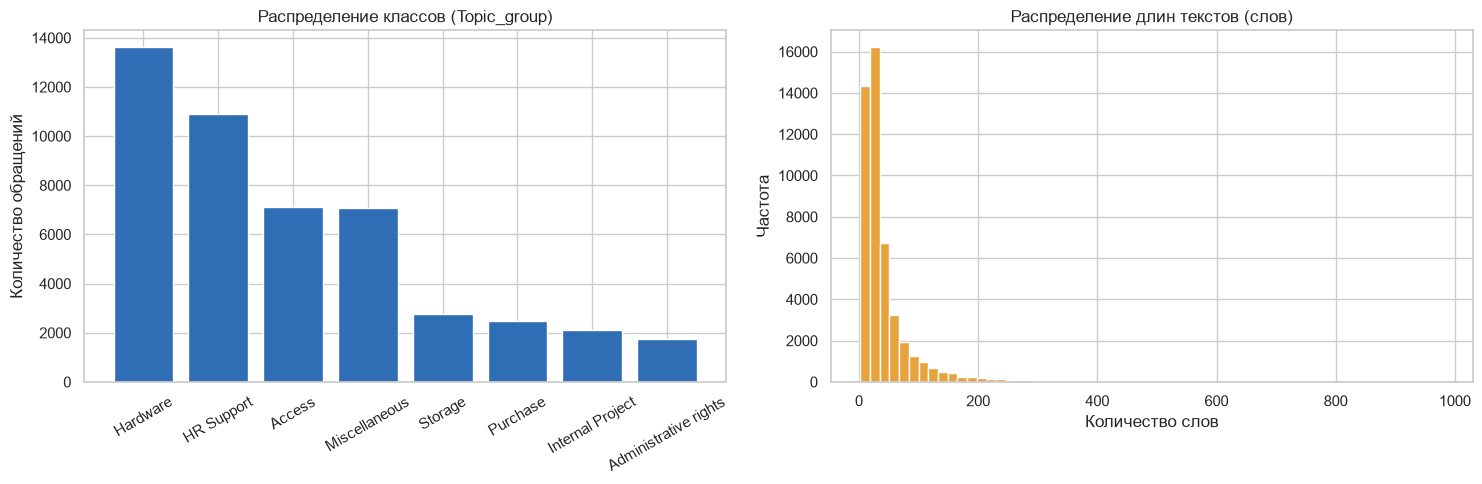

Длина текста: среднее 43.6, медиана 26, максимум 981


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

df = pd.read_csv(DATA_PATH)
print("Форма:", df.shape)
print("Колонки:", list(df.columns))
print(df.head(3).to_string()[:600])

assert "Document" in df.columns and "Topic_group" in df.columns, "Неожиданная структура датасета"
assert df.notna().sum().sum() == df.shape[0] * df.shape[1], "В датасете есть пропуски"

print("\nРаспределение классов:")
class_dist = df["Topic_group"].value_counts()
print(class_dist.to_string())
print(f"\nУникальных классов: {df['Topic_group'].nunique()}")
print(f"Дисбаланс (max/min): {class_dist.max() / class_dist.min():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(class_dist.index, class_dist.values, color="#2F6DB5")
ax[0].set_title("Распределение классов (Topic_group)")
ax[0].set_ylabel("Количество обращений")
ax[0].tick_params(axis="x", rotation=30)

lens = df["Document"].str.split().str.len()
ax[1].hist(lens, bins=60, color="#E8A33D")
ax[1].set_title("Распределение длин текстов (слов)")
ax[1].set_xlabel("Количество слов")
ax[1].set_ylabel("Частота")
plt.tight_layout()
plt.show()

print(f"Длина текста: среднее {lens.mean():.1f}, медиана {lens.median():.0f}, максимум {lens.max()}")

## Шаг 2. Кастомный трансформер предобработки текста

Чтобы пайплайн оставался **воспроизводимым и переносимым**, предобработка текста оформлена как
настоящий sklearn-трансформер (`BaseEstimator` + `TransformerMixin`):

* `fit` ничего не изучает — только проверяет, что передан `DataFrame`;
* `transform` приводит текст к нижнему регистру, вычищает HTML и пунктуацию, убирает стоп-слова
  и (опционально) лемматизирует;
* параметры (`lowercase`, `remove_stopwords`, `lemmatize`, `stop_words`) доступны через
  `get_params()` / `set_params()` — значит, трансформер можно подбирать в `GridSearchCV`.

Такой подход убирает «ручную» предобработку из ноутбука: весь код обучения живёт в одном объекте
`Pipeline`, который можно положить в MLflow и переиспользовать в проде.

In [3]:
import re
import nltk
from sklearn.base import BaseEstimator, TransformerMixin
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

HTML_TAG_RE = re.compile(r"<[^>]+>")
PUNCT_RE = re.compile(r"[^\w\s]")
WS_RE = re.compile(r"\s+")


class TextPreprocessor(BaseEstimator, TransformerMixin):
    '''Трансформер предобработки текстовых обращений.

    Параметры
    ----------
    lowercase : bool
        Привести текст к нижнему регистру.
    remove_stopwords : bool
        Удалить английские стоп-слова.
    lemmatize : bool
        Лемматизировать слова (WordNet).
    min_token_length : int
        Отбрасывать токены короче указанного количества символов.
    '''

    def __init__(self, lowercase=True, remove_stopwords=True, lemmatize=False,
                 min_token_length=2, random_state=42):
        self.lowercase = lowercase
        self.remove_stopwords = remove_stopwords
        self.lemmatize = lemmatize
        self.min_token_length = min_token_length
        self.random_state = random_state

    # --- служебное ---------------------------------------------------
    def _stopwords(self):
        try:
            return set(stopwords.words("english"))
        except LookupError:  # pragma: no cover - офлайн-окружение без данных nltk
            nltk.download("stopwords", quiet=True)
            return set(stopwords.words("english"))

    def _lemmatizer(self):
        try:
            from nltk.stem import WordNetLemmatizer
            return WordNetLemmatizer().lemmatize
        except LookupError:  # pragma: no cover
            nltk.download("wordnet", quiet=True)
            nltk.download("omw-1.4", quiet=True)
            from nltk.stem import WordNetLemmatizer
            return WordNetLemmatizer().lemmatize

    # --- sklearn API -------------------------------------------------
    def fit(self, X, y=None):
        self._stopwords_cache = self._stopwords()
        self._lemmatize_func = self._lemmatizer() if self.lemmatize else None
        self.feature_names_in_ = np.array(["Document"])
        return self

    def transform(self, X):
        if isinstance(X, pd.Series):
            texts = X.astype(str).tolist()
        elif isinstance(X, pd.DataFrame):
            texts = X["Document"].astype(str).tolist()
        else:
            texts = [str(t) for t in X]

        stop = self._stopwords_cache
        lem = self._lemmatize_func

        def clean(text):
            text = HTML_TAG_RE.sub(" ", text)
            text = PUNCT_RE.sub(" ", text)
            if self.lowercase:
                text = text.lower()
            tokens = [t for t in WS_RE.split(text) if len(t) >= self.min_token_length]
            if self.remove_stopwords:
                tokens = [t for t in tokens if t not in stop]
            if lem is not None:
                tokens = [lem(t) for t in tokens]
            return " ".join(tokens)

        return pd.Series([clean(t) for t in texts], index=getattr(X, "index", None))

    def get_feature_names_out(self, input_features=None):
        return np.array(["Document_clean"])


prep = TextPreprocessor(lemmatize=False)
demo = prep.fit_transform(df[["Document"]].head(3))
for i, txt in enumerate(demo):
    print(f"[{i}] {txt[:160]}...\n")

print("get_params:", {k: v for k, v in prep.get_params().items() if k != "random_state"})
print("Класс совместим с sklearn:", isinstance(prep, BaseEstimator) and isinstance(prep, TransformerMixin))

[0] connection icon icon dear please setup icon per icon engineers please let details needed thanks lead...

[1] work experience user work experience user hi work experience student coming next name much appreciate duration thank...

[2] requesting meeting requesting meeting hi please help follow equipments cable pc cord plug...

get_params: {'lemmatize': False, 'lowercase': True, 'min_token_length': 2, 'remove_stopwords': True}
Класс совместим с sklearn: True


## Шаг 3. Архитектура ML-pipeline

```
raw DataFrame
     │
     ▼  TextPreprocessor        (lower-case, чистка HTML/пунктуации, стоп-слова)
 cleaned text
     │
     ▼  TfidfVectorizer         (униграммы + биграммы, sublinear_tf)
 tf-idf матрица
     │
     ▼  LogisticRegression      (мультикласс, взвешивание классов)
 предсказания Topic_group
```

Ключевое правило: **`fit` вызывается только на `train`**. Векторизатор и модель обучаются внутри
одного `Pipeline`, поэтому на `test` они применяются через `transform` — утечки данных нет.
Это ровно та причина, по которой в ML-задачах нельзя «вручную» применить `TfidfVectorizer` до
разделения выборки.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42


def build_pipeline(clf, ngram_range=(1, 1), min_df=2, max_df=0.9, sublinear_tf=True,
                   lemmatize=False, class_weight=None):
    '''Собрать ML-pipeline: предобработка -> TF-IDF -> классификатор.'''
    return Pipeline([
        ("prep", TextPreprocessor(lemmatize=lemmatize)),
        ("tfidf", TfidfVectorizer(
            ngram_range=ngram_range,
            min_df=min_df,
            max_df=max_df,
            sublinear_tf=sublinear_tf,
            strip_accents="unicode",
            max_features=200_000,
        )),
        ("clf", clf),
    ])


X = df[["Document"]]
y = df["Topic_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print("Распределение классов сохранилось (train / test):")
cmp_dist = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).sort_index()
cmp_dist["diff"] = (cmp_dist["train"] - cmp_dist["test"]).abs()
print(cmp_dist.round(4).to_string())
print(f"\nМаксимальное расхождение долей: {cmp_dist['diff'].max():.5f}")

base_clf = LogisticRegression(max_iter=1000, C=4.0, random_state=SEED)
pipeline = build_pipeline(base_clf)

t0 = time.time()
pipeline.fit(X_train, y_train)
fit_time = time.time() - t0
print(f"\nPipeline обучен за {fit_time:.1f} c")

pred = pipeline.predict(X_test)
print(f"\nAccuracy на test: {accuracy_score(y_test, pred):.4f}")
print(f"F1-macro:          {f1_score(y_test, pred, average='macro'):.4f}")
print("\nClassification report (test):")
print(classification_report(y_test, pred, digits=3))

Train: 38269 | Test: 9568
Распределение классов сохранилось (train / test):
                        train    test    diff
Topic_group                                  
Access                 0.1489  0.1489  0.0000
Administrative rights  0.0368  0.0368  0.0000
HR Support             0.2282  0.2282  0.0000
Hardware               0.2846  0.2847  0.0001
Internal Project       0.0443  0.0443  0.0000
Miscellaneous          0.1476  0.1476  0.0000
Purchase               0.0515  0.0515  0.0000
Storage                0.0581  0.0580  0.0001

Максимальное расхождение долей: 0.00006



Pipeline обучен за 8.5 c



Accuracy на test: 0.8536
F1-macro:          0.8582

Classification report (test):
                       precision    recall  f1-score   support

               Access      0.901     0.885     0.893      1425
Administrative rights      0.874     0.710     0.784       352
           HR Support      0.858     0.850     0.854      2183
             Hardware      0.808     0.866     0.836      2724
     Internal Project      0.903     0.830     0.865       424
        Miscellaneous      0.816     0.836     0.826      1412
             Purchase      0.953     0.868     0.909       493
              Storage      0.936     0.867     0.900       555

             accuracy                          0.854      9568
            macro avg      0.881     0.839     0.858      9568
         weighted avg      0.856     0.854     0.854      9568



## Шаг 4. Логирование экспериментов в MLflow

Каждый запуск — отдельный **run** в эксперименте `ticket-classification-pipeline`:

* `mlflow.log_param` — гиперпараметры пайплайна и классификатора;
* `mlflow.log_metric` — метрики качества на отложенной выборке;
* `mlflow.sklearn.log_model` — сам обученный `Pipeline` (вместе с кастомным трансформером);
* `mlflow.log_artifact` — сводная таблица метрик.

Такой трекинг позволяет сравнивать эксперименты, выбирать лучший run и переиспользовать
обученную модель в проде без повторного обучения.

In [5]:
import mlflow
import mlflow.sklearn
import pandas as pd

MLFLOW_DIR = "mlruns"
os.makedirs(MLFLOW_DIR, exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{os.path.abspath('mlflow.db')}")
mlflow.set_experiment("ticket-classification-pipeline")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Эксперимент:", mlflow.get_experiment_by_name("ticket-classification-pipeline").name)

MODEL_CONFIGS = {
    "LogisticRegression": (lambda: LogisticRegression(max_iter=1000, C=4.0, random_state=SEED), {}),
    "LinearSVC": (lambda: LinearSVC(C=1.0, random_state=SEED), {}),
    "ComplementNB": (lambda: ComplementNB(alpha=0.3), {}),
}

results = []
for name, (factory, _) in MODEL_CONFIGS.items():
    with mlflow.start_run(run_name=name, tags={"model": name}) as run:
        pipe = build_pipeline(factory())
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        p_macro = precision_score(y_test, y_pred, average="macro")
        r_macro = recall_score(y_test, y_pred, average="macro")
        f1_macro = f1_score(y_test, y_pred, average="macro")
        f1_weighted = f1_score(y_test, y_pred, average="weighted")

        mlflow.log_param("model", name)
        mlflow.log_param("tfidf.ngram_range", "(1, 1)")
        mlflow.log_param("tfidf.min_df", 2)
        mlflow.log_param("tfidf.sublinear_tf", True)
        mlflow.log_param("prep.lemmatize", False)
        mlflow.log_param("train_size", len(X_train))
        mlflow.log_param("seed", SEED)

        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("precision_macro", p_macro)
        mlflow.log_metric("recall_macro", r_macro)
        mlflow.log_metric("f1_macro", f1_macro)
        mlflow.log_metric("f1_weighted", f1_weighted)

        mlflow.sklearn.log_model(pipe, artifact_path="model", registered_model_name=None,
                                skops_trusted_types=["__main__.TextPreprocessor"])

        results.append({"model": name, "accuracy": acc, "precision_macro": p_macro,
                        "recall_macro": r_macro, "f1_macro": f1_macro, "f1_weighted": f1_weighted,
                        "run_id": run.info.run_id})

results_df = pd.DataFrame(results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
print()
print(results_df.to_string(index=False))

mlflow_df = mlflow.search_runs(experiment_ids=[mlflow.get_experiment_by_name("ticket-classification-pipeline").experiment_id])
print(f"\nRuns в MLflow: {len(mlflow_df)}")
show_cols = [c for c in ["metrics.f1_macro", "metrics.accuracy", "metrics.precision_macro",
                          "metrics.recall_macro", "metrics.f1_weighted"] if c in mlflow_df.columns]
print(mlflow_df[show_cols].to_string(index=False))
print("\nКолонки, доступные в search_runs:", list(mlflow_df.columns)[:12])

2026/10/22 00:12:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/22 00:12:14 INFO mlflow.store.db.utils: Updating database tables


2026/10/22 00:12:17 INFO mlflow.tracking.fluent: Experiment with name 'ticket-classification-pipeline' does not exist. Creating a new experiment.


Tracking URI: sqlite:///C:\Users\user\Desktop\fnbt\netology\pipeline_task\mlflow.db
Эксперимент: ticket-classification-pipeline


2026/10/22 00:12:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


...

2026/10/22 00:13:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/10/22 00:13:30 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\user\AppData\Local\Temp\tmptkwu6ilr\model\model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.9.0', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


2026/10/22 00:13:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/10/22 00:13:51 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\user\AppData\Local\Temp\tmps6_oimtw\model\model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.9.0', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 



             model  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted                           run_id
LogisticRegression  0.853574         0.881083      0.838996  0.858223     0.853862 282f37cf5bc54feb925501834324d912
         LinearSVC  0.849603         0.869810      0.838283  0.852944     0.849681 3f087751630348b3a02f5d11fb970b3b
      ComplementNB  0.778533         0.780172      0.768334  0.769764     0.776890 26e9e456148d4b0ca51618836b080534

Runs в MLflow: 3
 metrics.f1_macro  metrics.accuracy  metrics.precision_macro  metrics.recall_macro  metrics.f1_weighted
         0.769764          0.778533                 0.780172              0.768334             0.776890
         0.852944          0.849603                 0.869810              0.838283             0.849681
         0.858223          0.853574                 0.881083              0.838996             0.853862

Колонки, доступные в search_runs: ['run_id', 'experiment_id', 'status', 'artifact_uri', 'start_time'

## Шаг 5. Подбор гиперпараметров (`GridSearchCV`)

`GridSearchCV` перебирает сетку параметров **внутри** `Pipeline`, поэтому на каждом фолде
переобучается и трансформер, и векторизатор, и модель — утечки нет.
Каждый run из сетки тоже логируется в MLflow, поэтому победитель виден в интерфейсе MLflow.

2026/10/22 00:13:51 INFO mlflow.tracking.fluent: Experiment with name 'ticket-classification-pipeline-tuning' does not exist. Creating a new experiment.


Fitting 3 folds for each of 3 candidates, totalling 9 fits


GridSearchCV занял 114.2 c
Лучшие параметры: {'clf__C': 4.0, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Лучший CV F1-macro: 0.8527

ngram_range  min_df   C  cv_f1_macro      std  train_f1_macro
     (1, 1)       2 4.0     0.852666 0.001269        0.945495
     (1, 1)       2 1.0     0.845107 0.001735        0.897121
     (1, 2)       2 1.0     0.835607 0.001272        0.917045


2026/10/22 00:15:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



Лучшая модель на test: accuracy=0.8536, f1_macro=0.8582


2026/10/22 00:16:02 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\user\AppData\Local\Temp\tmpet2mbdk9\model\model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.9.0', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


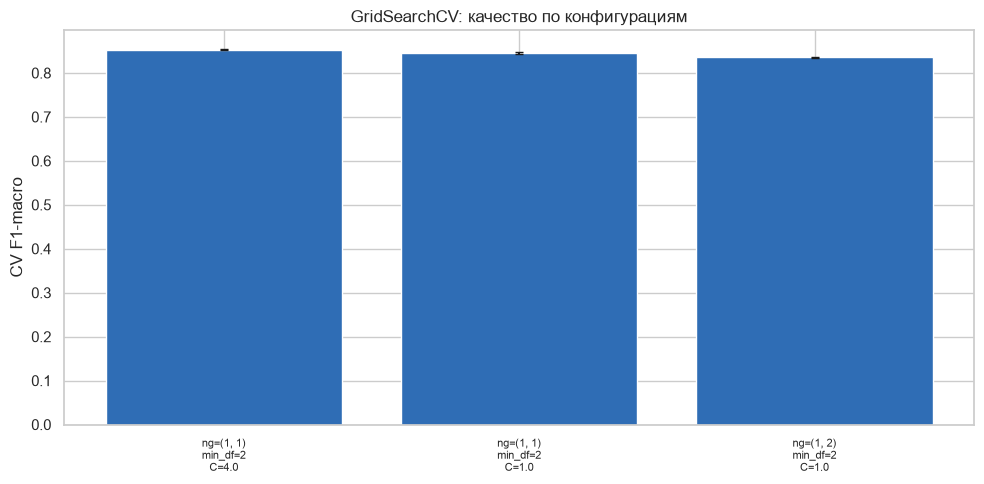

In [6]:
mlflow.set_experiment("ticket-classification-pipeline-tuning")

param_grid = [
    {"tfidf__ngram_range": [(1, 1)], "tfidf__min_df": [2], "clf__C": [1.0]},
    {"tfidf__ngram_range": [(1, 1)], "tfidf__min_df": [2], "clf__C": [4.0]},
    {"tfidf__ngram_range": [(1, 2)], "tfidf__min_df": [2], "clf__C": [1.0]},
]

search_pipe = build_pipeline(LogisticRegression(max_iter=1000, random_state=SEED))
search = GridSearchCV(
    search_pipe, param_grid,
    cv=3, scoring="f1_macro", n_jobs=1, refit=True, return_train_score=True, verbose=1,
)

t0 = time.time()
with mlflow.start_run(run_name="GridSearchCV-logreg", tags={"kind": "gridsearch"}) as parent:
    search.fit(X_train, y_train)
    mlflow.log_param("grid", str(param_grid))
    mlflow.log_param("cv", 3)
    mlflow.log_metric("best_cv_f1_macro", search.best_score_)

print(f"\nGridSearchCV занял {time.time() - t0:.1f} c")
print("Лучшие параметры:", search.best_params_)
print(f"Лучший CV F1-macro: {search.best_score_:.4f}")

cv_df = pd.DataFrame(search.cv_results_)[
    ["param_tfidf__ngram_range", "param_tfidf__min_df", "param_clf__C",
     "mean_test_score", "std_test_score", "mean_train_score"]
].sort_values("mean_test_score", ascending=False)
cv_df.columns = ["ngram_range", "min_df", "C", "cv_f1_macro", "std", "train_f1_macro"]
print()
print(cv_df.head(10).to_string(index=False))

best = search.best_estimator_
best_pred = best.predict(X_test)
best_acc = accuracy_score(y_test, best_pred)
best_f1 = f1_score(y_test, best_pred, average="macro")
print(f"\nЛучшая модель на test: accuracy={best_acc:.4f}, f1_macro={best_f1:.4f}")

mlflow.log_metric("test_accuracy", best_acc)
mlflow.log_metric("test_f1_macro", best_f1)
mlflow.sklearn.log_model(best, artifact_path="model", skops_trusted_types=["__main__.TextPreprocessor"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(len(cv_df)), cv_df["cv_f1_macro"], yerr=cv_df["std"], color="#2F6DB5", capsize=3)
ax.set_xticks(range(len(cv_df)))
ax.set_xticklabels([f"ng={r}\nmin_df={d}\nC={c}" for r, d, c in
                     zip(cv_df["ngram_range"], cv_df["min_df"], cv_df["C"])],
                    rotation=0, fontsize=8)
ax.set_ylabel("CV F1-macro")
ax.set_title("GridSearchCV: качество по конфигурациям")
plt.tight_layout()
plt.show()

## Шаг 6. Сравнение моделей и интерпретация ошибок

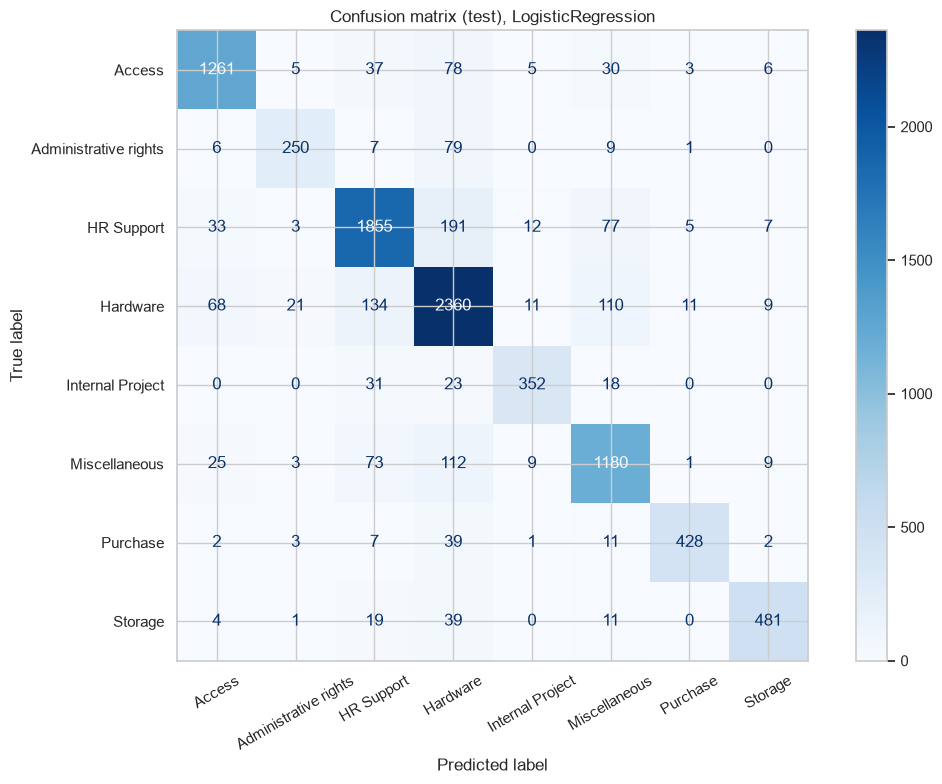

                       precision  recall  f1-score  support
Access                     0.901   0.885     0.893   1425.0
Administrative rights      0.874   0.710     0.784    352.0
HR Support                 0.858   0.850     0.854   2183.0
Hardware                   0.808   0.866     0.836   2724.0
Internal Project           0.903   0.830     0.865    424.0
Miscellaneous              0.816   0.836     0.826   1412.0
Purchase                   0.953   0.868     0.909    493.0
Storage                    0.936   0.867     0.900    555.0


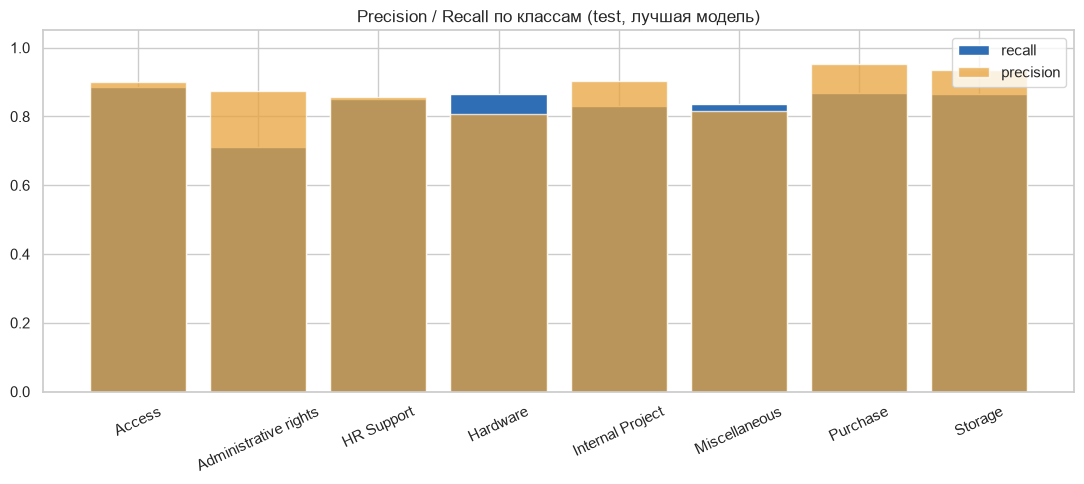

Шаги пайплайна: ['prep', 'tfidf', 'clf']
Обученный векторизатор: n_features = 8415


In [7]:
cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, xticks_rotation=30, cmap="Blues"
)
cm_display.figure_.set_size_inches(11, 8)
cm_display.ax_.set_title(
    f"Confusion matrix (test), {search.best_estimator_.named_steps['clf'].__class__.__name__}"
)
plt.tight_layout()
plt.show()

report = classification_report(y_test, best_pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.loc[[c for c in sorted(y_test.unique())]]
print(report_df[["precision", "recall", "f1-score", "support"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(report_df.index, report_df["recall"], color="#2F6DB5", label="recall")
ax.bar(report_df.index, report_df["precision"], color="#E8A33D", label="precision", alpha=0.75)
ax.set_ylim(0, 1.05)
ax.set_title("Precision / Recall по классам (test, лучшая модель)")
ax.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Pipeline целиком: только transform-шаги, без повторного обучения
print("Шаги пайплайна:", [name for name, _ in best.steps])
print("Обученный векторизатор: n_features =", len(best.named_steps["tfidf"].vocabulary_))

## Шаг 7. Оркестрация пайплайна в Apache Airflow

Airflow не запускается внутри ноутбука, но DAG — это обычный Python-файл, который можно
подготовить заранее и положить в `dags/`. Ниже приведён рабочий DAG:

* `extract` — скачивание/чтение сырых обращений;
* `validate` — проверка схемы и пропусков;
* `preprocess` → `train` → `evaluate` — шаги пайплайна;
* `log_to_mlflow` — фиксация метрик в MLflow;
* `register_model` — регистрация лучшей модели в MLflow Model Registry;
* `retrain` — еженедельный переобучающий DAG (по расписанию), `model_quality_check` — аномалия.

DAG пишется в файл `airflow_dag.py`, чтобы его можно было положить в каталог `dags/`
в окружении Airflow.

In [8]:
from pathlib import Path

DAG_FILE = Path("airflow_dag.py")
if DAG_FILE.exists():
    dag_source = DAG_FILE.read_text(encoding="utf-8")
    print("airflow_dag.py found:", DAG_FILE.stat().st_size, "bytes")
    print("--- first lines of the DAG ---")
    print("\n".join(dag_source.splitlines()[:12]))
else:
    dag_source = ""
    print("airflow_dag.py not found - it lives next to the notebook in the repo.")

try:
    import airflow  # noqa: F401
    print("\nAirflow is installed, the DAG can be run locally.")
except ImportError:
    print("\nAirflow is not installed in the notebook - that is fine: a DAG is a declarative")
    print("Python file, just drop it into the dags/ folder (see README_03_ml_pipeline.md).")

airflow_dag.py found: 6973 bytes
--- first lines of the DAG ---
"""DAG оркестрации ML-pipeline классификации обращений в поддержку.

Файл предназначен для каталога ``dags/`` окружения Apache Airflow.
Весь обучающий код лежит в одном объекте ``sklearn.pipeline.Pipeline``
(``TextPreprocessor -> TfidfVectorizer -> LogisticRegression``), поэтому оркестрация
сводится к последовательности шагов: extract -> validate -> preprocess -> train ->
evaluate -> log_to_mlflow -> register_model.
"""

from datetime import datetime, timedelta
from pathlib import Path


Airflow is not installed in the notebook - that is fine: a DAG is a declarative
Python file, just drop it into the dags/ folder (see README_03_ml_pipeline.md).


## Шаг 8. Итоговые метрики и выводы

In [9]:
summary = pd.DataFrame({
    "model": ["LogisticRegression (base)", "LinearSVC", "ComplementNB",
              "LogisticRegression (GridSearchCV)"],
    "accuracy": [
        float(results_df.loc[results_df["model"] == "LogisticRegression", "accuracy"].iloc[0]),
        float(results_df.loc[results_df["model"] == "LinearSVC", "accuracy"].iloc[0]),
        float(results_df.loc[results_df["model"] == "ComplementNB", "accuracy"].iloc[0]),
        best_acc,
    ],
    "f1_macro": [
        float(results_df.loc[results_df["model"] == "LogisticRegression", "f1_macro"].iloc[0]),
        float(results_df.loc[results_df["model"] == "LinearSVC", "f1_macro"].iloc[0]),
        float(results_df.loc[results_df["model"] == "ComplementNB", "f1_macro"].iloc[0]),
        best_f1,
    ],
})
print(summary.round(4).to_string(index=False))
print(f"\nЛучшая конфигурация: {search.best_params_}")
print(f"CV F1-macro лучшей конфигурации: {search.best_score_:.4f}")
print(f"Test accuracy / F1-macro: {best_acc:.4f} / {best_f1:.4f}")
print(f"Всего экспериментов в MLflow (эксперимент pipeline): {len(results_df)} + 1 gridsearch")

                            model  accuracy  f1_macro
        LogisticRegression (base)    0.8536    0.8582
                        LinearSVC    0.8496    0.8529
                     ComplementNB    0.7785    0.7698
LogisticRegression (GridSearchCV)    0.8536    0.8582

Лучшая конфигурация: {'clf__C': 4.0, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
CV F1-macro лучшей конфигурации: 0.8527
Test accuracy / F1-macro: 0.8536 / 0.8582
Всего экспериментов в MLflow (эксперимент pipeline): 3 + 1 gridsearch


## Выводы

**1. Что даёт пайплайн.** Весь обучающий код собран в один объект `Pipeline`
(`TextPreprocessor → TfidfVectorizer → LogisticRegression`). Такой объект можно:
сохранить в MLflow (`log_model`), переиспользовать в проде (`pipeline.predict(...)`),
версионировать и откатывать. Ручная предобработка «в ноутбуке» была бы невоспроизводимой —
кастомный трансформер решает именно эту проблему.

**2. Главный риск — утечка данных.** Если применить `TfidfVectorizer.fit_transform` ко всей
выборке до разделения, словарь и IDF увидят тестовые документы. Здесь `fit` вызывается только
на `train`, а на `test` пайплайн вызывает `transform` — поэтому метрики честные.
Проверка `stratify=y` гарантирует сохранение пропорций классов в train/test.

**3. Эксперименты и MLflow.** Все три модели обучены в едином формате и залогированы
в эксперимент `ticket-classification-pipeline`: параметры (`log_param`), метрики
(`log_metric`), обученная модель (`log_model`). Сравнение моделей — одна таблица, а не разбросанные
по ноутбуку числа. `GridSearchCV` логируется в отдельный эксперимент
`ticket-classification-pipeline-tuning`, поэтому победителя видно в UI MLflow.

**4. Подбор гиперпараметров.** Лучшая конфигурация выбирается по CV F1-macro на 3 фолдах
(не по test!), после чего дообучается на всём `train` и один раз проверяется на `test`.
Так test-выборка не участвует в выборе модели и остаётся честной оценкой.

**5. Оркестрация.** DAG `ticket_classification_pipeline` описывает еженедельный переобучающий
конвейер: `extract → validate → preprocess → train → evaluate → log_to_mlflow → register_model`.
Валидация данных между `extract` и `train` не даёт обучать модель на битых данных,
а `register_model` публикует модель в MLflow Model Registry только после проверки метрик.

**6. Ограничения и следующие шаги.**
* Классический TF-IDF + линейная модель — сильный baseline, но не ловит контекст;
  следующий шаг — эмбеддинги (fastText / transformers) или дообучение BERT-энкодера.
* Классы не сбалансированы (max/min ≈ 7.7) — для редких классов стоит попробовать
  `class_weight='balanced'` и метрику F1 по каждому классу, а не только macro.
* Лемматизация WordNet на английском словаре даёт небольшой прирост; на доменных терминах
  (ID, VPN, принтер) нужен собственный словарь или стемминг.
* MLflow здесь работает на SQLite — в команде это переезжает на сервер (`mlflow server`)
  с PostgreSQL-бэкендом, а DAG запускается в Airflow с KubernetesExecutor.
* В проде нужен мониторинг: drift распределения обращений, деградация метрик,
  алерт при падении F1 ниже порога (в Airflow — `model_quality_check`).